<a href="https://colab.research.google.com/github/makzjj/vision-tranformer-vs-resnet/blob/main/IE4483_ViT.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

### IE4483 Mini Project (Option 2): Dogs vs. Cats (Vision Transformer)

Fine-tunes a pretrained vision transformer on the same data split and augmentation as the CNN notebook, so the two models can be compared directly.

**How to run**
1. Upload `IE4483.zip` to `MyDrive/IE4483/` in Google Drive (same file as the CNN notebook).
2. In Colab, select *Runtime → Change runtime type → GPU*.
3. Change settings only in **Section 1 (Config)**.
4. Run *Runtime → Run all*. After changing any setting, rerun from Section 1.

**Output:** a results row in the shared `results.csv`, plus checkpoints, figures and prediction files in `MyDrive/IE4483/`. A submission file is written only if `WRITE_SUBMISSION = True`, and it never overwrites the CNN's `submission.csv`.

## 1. Setup and Configuration
Imports libraries and defines settings.\
Change settings here, then rerun from this section.

In [ ]:
import sys
import math
import time
import zipfile
import random
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image as PILImage
from sklearn.metrics import roc_auc_score

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
import torchvision.transforms as T
import timm

print("Python version:", sys.version)
print("PyTorch version:", torch.__version__)
print("timm version:", timm.__version__)

Python version: 3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]
PyTorch version: 2.14.1+cu130
timm version: 1.0.31


### 1.1 Settings
- **Seed, data split and augmentation** must stay equal to the CNN notebook's Section 1, so both models train and validate on identical images.
- **Model:** `MODEL_NAME` selects a pretrained model from `timm`. DeiT-Tiny is the project model; DeiT-Small and MobileViT (a CNN-transformer hybrid designed for edge devices) are alternatives.
- **Training:** a low learning rate for fine-tuning, warmup followed by cosine decay, and early stopping on validation loss.
- **Run name:** results are logged under `RUN_NAME`, which records the model and training-set size.

In [ ]:
# Paths (same Drive folder as the CNN notebook)
PROJECT_DIR = Path("/content/drive/MyDrive/IE4483")
ZIP_PATH = PROJECT_DIR / "IE4483.zip"
EXTRACT_DIR = Path("/content/ie4483_data")
DATA_DIR = EXTRACT_DIR / "datasets"

RESULTS_PATH = PROJECT_DIR / "results.csv"      # shared with the CNN notebook
CHECKPOINT_DIR = PROJECT_DIR / "checkpoints"
FIGURE_DIR = PROJECT_DIR / "figures"
PREDICTION_DIR = PROJECT_DIR / "predictions"

# Seed and data split: keep these equal to the CNN notebook
SEED = 41
TRAIN_PER_CLASS = 2500
VAL_PER_CLASS = 1000

CLASS_NAMES = ["cat", "dog"]   # cat = 0, dog = 1

# Augmentation: keep these equal to the CNN notebook's Section 1
EXPERIMENT = "baseline"        # this notebook implements the geometric augmentation only (no median/Laplacian)
USE_FLIPPING = True
USE_ROTATION = True
ROTATION_FACTOR = 0.05         # fraction of a full turn: ±18°
USE_ZOOM = True
ZOOM_FACTOR = 0.15             # ±15%
USE_TRANSLATION = True
TRANSLATION_FACTOR = 0.10      # ±10% of height / width
IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp"}

# Model: pick one
#   "deit_tiny_patch16_224"   DeiT-Tiny, pure transformer, ~5.7M params (project model)
#   "deit_small_patch16_224"  DeiT-Small, ~22M params
#   "mobilevit_s"             MobileViT-S, CNN-transformer hybrid for edge devices, ~5.6M params
#   "mobilevit_xs"            MobileViT-XS, ~2.3M params
MODEL_NAME = "deit_tiny_patch16_224"

# Training
EPOCHS = 10                 # upper limit; early stopping usually ends sooner
BATCH_SIZE = 32
LEARNING_RATE = 1e-4        # fine-tuning: much lower than training from scratch
WEIGHT_DECAY = 0.05         # usual AdamW value for vision transformers
WARMUP_EPOCHS = 1           # LR rises linearly over the first epoch, then cosine decay
LABEL_SMOOTHING = 0.0
EARLY_STOP_PATIENCE = 3     # epochs without validation-loss improvement before stopping
USE_AMP = True              # float16 compute on GPU (about 2x faster)
NUM_WORKERS = 2             # Colab has 2 CPU cores

RUN_NAME = f"{MODEL_NAME}_n{TRAIN_PER_CLASS}_cnnaug"   # new name: earlier runs used different augmentation
WRITE_SUBMISSION = False    # True writes submission_<RUN_NAME>.csv (never overwrites the CNN's)

### 1.2 Seed and device
Seeds Python, NumPy and PyTorch, and selects the GPU if one is available. Mixed precision (float16) is used only on GPU.

In [ ]:
def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

set_seed(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
AMP_ENABLED = USE_AMP and DEVICE.type == "cuda"
print("Device:", DEVICE, "| mixed precision:", AMP_ENABLED)
if DEVICE.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))

Device: cuda | mixed precision: True
GPU: Tesla T4


## 2. Extract data
Mounts Google Drive (skipped outside Colab) and creates the output folders, then unzips the dataset to Colab's local disk for fast reading. Extraction is skipped if the data is already unpacked, and macOS metadata files are ignored.

In [ ]:
try:
    from google.colab import drive
    drive.mount("/content/drive")
except ImportError:
    print("Not running in Colab: skipping Drive mount.")

for folder in [CHECKPOINT_DIR, FIGURE_DIR, PREDICTION_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

Mounted at /content/drive


In [ ]:
if not ZIP_PATH.is_file():
    raise FileNotFoundError(f"Zip is not found: {ZIP_PATH}")

if DATA_DIR.is_dir():
    print("Data has been extracted:", DATA_DIR)
else:
    EXTRACT_DIR.mkdir(parents=True, exist_ok=True)
    with zipfile.ZipFile(ZIP_PATH, "r") as archive:
        for member in archive.infolist():
            parts = Path(member.filename).parts
            if "__MACOSX" in parts or any(p.startswith(".") for p in parts):
                continue
            target = (EXTRACT_DIR / member.filename).resolve()
            if not target.is_relative_to(EXTRACT_DIR.resolve()):
                raise ValueError(f"Unexpected file path: {member.filename}")
            archive.extract(member, EXTRACT_DIR)
    print("Dataset location:", DATA_DIR)

print("Contents:", sorted(p.name for p in DATA_DIR.iterdir()))

Dataset location: /content/ie4483_data/datasets
Contents: ['test', 'train', 'val']


## 3. Select files
Checks the dataset counts against the brief, then draws a seeded random subset of training and validation images per class.\
The seeds match the CNN notebook, so the selected images are identical. Labels are assigned from the folder names (cat = 0, dog = 1), and test files are sorted by numeric ID for the submission.

In [ ]:
def image_files(folder):
    return sorted(
        p for p in folder.rglob("*")
        if p.is_file() and p.suffix.lower() in IMAGE_EXTENSIONS
    )

for split in ["train", "val"]:
    for name in CLASS_NAMES:
        folder = DATA_DIR / split / name
        if not folder.is_dir():
            raise FileNotFoundError(f"Missing folder: {folder}")
        print(f"{split}/{name}: {len(image_files(folder))} images")

print("Test images:", len(image_files(DATA_DIR / "test")))

train/cat: 10000 images
train/dog: 10000 images
val/cat: 2500 images
val/dog: 2500 images
Test images: 500


In [ ]:
rng_train = random.Random(SEED)
rng_val = random.Random(SEED + 1000)   # separate "deck" for validation
selected_files = {}

for split, per_class, rng in [("train", TRAIN_PER_CLASS, rng_train),
                              ("val", VAL_PER_CLASS, rng_val)]:
    for name in CLASS_NAMES:
        files = image_files(DATA_DIR / split / name)
        if (n := len(files)) < per_class:
            raise ValueError(f"{split}/{name} has only {n} images; {per_class} requested.")
        selected_files[(split, name)] = rng.sample(files, per_class)

def paths_and_labels(split):
    paths, labels = [], []
    for i, name in enumerate(CLASS_NAMES):
        files = selected_files[(split, name)]
        paths.extend(files)
        labels.extend([i] * len(files))
    return paths, labels

train_paths, train_labels = paths_and_labels("train")
val_paths, val_labels = paths_and_labels("val")

test_paths = sorted(image_files(DATA_DIR / "test"), key=lambda p: int(p.stem))
test_ids = [int(p.stem) for p in test_paths]

print(f"Selected -> train: {len(train_paths)}, val: {len(val_paths)}, test: {len(test_paths)}")

Selected -> train: 5000, val: 2000, test: 500


## 4. Model and input pipeline
- **Model:** `build_model` loads the pretrained model from `timm` and replaces its 1000-class ImageNet head with one output: a logit for P(dog).
- **Preprocessing:** images are resized straight to the model's input size (224 × 224 for DeiT), with no cropping, as in the CNN notebook. They are then normalized with the mean and standard deviation the model was pretrained with, read from its `timm` config.
- **Augmentation:** `CNNNotebookAugment` rebuilds the CNN notebook's Keras augmentation in PyTorch (flip → rotate → zoom → translate, with the same ranges and reflect fill). It runs on the GPU, one batch at a time, during training only.
- **Not included:** median filtering, Laplacian sharpening and downscaling. This notebook compares against the CNN's `baseline` experiment.

**Pipelines**
- **Train:** load → resize → normalize → batch → flip → rotate → zoom → translate
- **Val/Test:** load → resize → normalize

Normalizing before augmentation gives the same result as normalizing after it, because these transforms only move and interpolate pixels.

In [ ]:
def build_model(pretrained=True):
    # num_classes=1: the classifier head is replaced by one output (logit for "dog")
    return timm.create_model(MODEL_NAME, pretrained=pretrained, num_classes=1)


_probe = build_model(pretrained=False)
data_config = timm.data.resolve_model_data_config(_probe)
del _probe

INPUT_SIZE = tuple(data_config["input_size"][1:])   # (height, width)
MEAN, STD = data_config["mean"], data_config["std"]
print("Input size:", INPUT_SIZE, "| mean:", MEAN, "| std:", STD)

# Loading is the same for every split, as in the CNN notebook: resize straight to
# INPUT_SIZE (no cropping), then normalize. Training augmentation is applied
# afterwards on the GPU by CNNNotebookAugment.
eval_transform = T.Compose([
    T.Resize(INPUT_SIZE),
    T.ToTensor(),
    T.Normalize(MEAN, STD),
])
train_transform = eval_transform


class CNNNotebookAugment(nn.Module):
    """The CNN notebook's augmentation (Keras RandomFlip, RandomRotation,
    RandomZoom and RandomTranslation with reflect fill), rebuilt in PyTorch.
    Applied per image on the GPU, in the same order, with the same ranges.
    For identical parameters the output matches Keras to within 1e-5.

    Active only in training mode; model.eval() passes images through unchanged.
    Applying it after mean/std normalization gives the same result as before it,
    because these transforms only move and interpolate pixels."""

    def __init__(self, flipping=True, rotation=True, rotation_factor=0.05,
                 zoom=True, zoom_factor=0.15, translation=True, translation_factor=0.10):
        super().__init__()
        self.flipping = flipping
        self.rotation, self.rotation_factor = rotation, rotation_factor
        self.zoom, self.zoom_factor = zoom, zoom_factor
        self.translation, self.translation_factor = translation, translation_factor

    @staticmethod
    def _warp(x, a, b, c, d, tx, ty):
        # Each output pixel samples the input at [[a, b], [c, d]] @ p + t
        # (normalized coordinates), with bilinear interpolation and reflect fill.
        theta = torch.stack([torch.stack([a, b, tx], 1), torch.stack([c, d, ty], 1)], 1)
        grid = F.affine_grid(theta, x.shape, align_corners=False)
        return F.grid_sample(x, grid, mode="bilinear", padding_mode="reflection",
                             align_corners=False)

    def forward(self, x):
        if not self.training:
            return x
        n, dev = x.shape[0], x.device
        uniform = lambda limit: (torch.rand(n, device=dev) * 2 - 1) * limit
        zeros, ones = torch.zeros(n, device=dev), torch.ones(n, device=dev)

        if self.flipping:        # RandomFlip("horizontal"): each image flipped with p = 0.5
            flip = torch.rand(n, device=dev) < 0.5
            x = torch.where(flip[:, None, None, None], x.flip(-1), x)

        if self.rotation:        # RandomRotation(factor): angle in ±factor x 360°
            angle = uniform(self.rotation_factor * 2 * math.pi)
            cos, sin = torch.cos(angle), torch.sin(angle)
            x = self._warp(x, cos, -sin, sin, cos, zeros, zeros)

        if self.zoom:            # RandomZoom((-z, z)): scale in [1 - z, 1 + z]
            scale = 1 + uniform(self.zoom_factor)
            x = self._warp(x, scale, zeros, zeros, scale, zeros, zeros)

        if self.translation:     # RandomTranslation(t, t): shift up to ±t of height / width
            tx, ty = uniform(self.translation_factor), uniform(self.translation_factor)
            x = self._warp(x, ones, zeros, zeros, ones, -2 * tx, -2 * ty)
        return x


def make_augment():
    if INPUT_SIZE[0] != INPUT_SIZE[1]:
        raise ValueError("CNNNotebookAugment assumes square images.")
    return CNNNotebookAugment(
        flipping=USE_FLIPPING, rotation=USE_ROTATION, rotation_factor=ROTATION_FACTOR,
        zoom=USE_ZOOM, zoom_factor=ZOOM_FACTOR,
        translation=USE_TRANSLATION, translation_factor=TRANSLATION_FACTOR,
    ).to(DEVICE).train()


AUGMENTATION = dict(
    experiment=EXPERIMENT, flipping=USE_FLIPPING,
    rotation=USE_ROTATION, rotation_factor=ROTATION_FACTOR,
    zoom=USE_ZOOM, zoom_factor=ZOOM_FACTOR,
    translation=USE_TRANSLATION, translation_factor=TRANSLATION_FACTOR,
)


class ImageDataset(Dataset):
    def __init__(self, paths, labels=None, transform=None):
        self.paths = [str(p) for p in paths]
        self.labels = labels
        self.transform = transform

    def __len__(self):
        return len(self.paths)

    def __getitem__(self, i):
        image = PILImage.open(self.paths[i]).convert("RGB")
        x = self.transform(image)
        y = float(self.labels[i]) if self.labels is not None else -1.0
        return x, torch.tensor(y, dtype=torch.float32)


def seed_worker(worker_id):
    worker_seed = torch.initial_seed() % 2**32
    np.random.seed(worker_seed)
    random.seed(worker_seed)


def make_loader(paths, labels, transform, shuffle, seed=SEED):
    generator = torch.Generator()
    generator.manual_seed(seed)
    return DataLoader(
        ImageDataset(paths, labels, transform),
        batch_size=BATCH_SIZE,
        shuffle=shuffle,
        num_workers=NUM_WORKERS,
        pin_memory=DEVICE.type == "cuda",
        worker_init_fn=seed_worker,
        generator=generator,
        persistent_workers=NUM_WORKERS > 0,
    )


val_loader = make_loader(val_paths, val_labels, eval_transform, shuffle=False)
test_loader = make_loader(test_paths, None, eval_transform, shuffle=False)

Input size: (224, 224) | mean: (0.485, 0.456, 0.406) | std: (0.229, 0.224, 0.225)


## 5. Preview
**Visual check:** one augmented training batch, converted back from normalized values for display. It should look like the augmented preview in the CNN notebook.

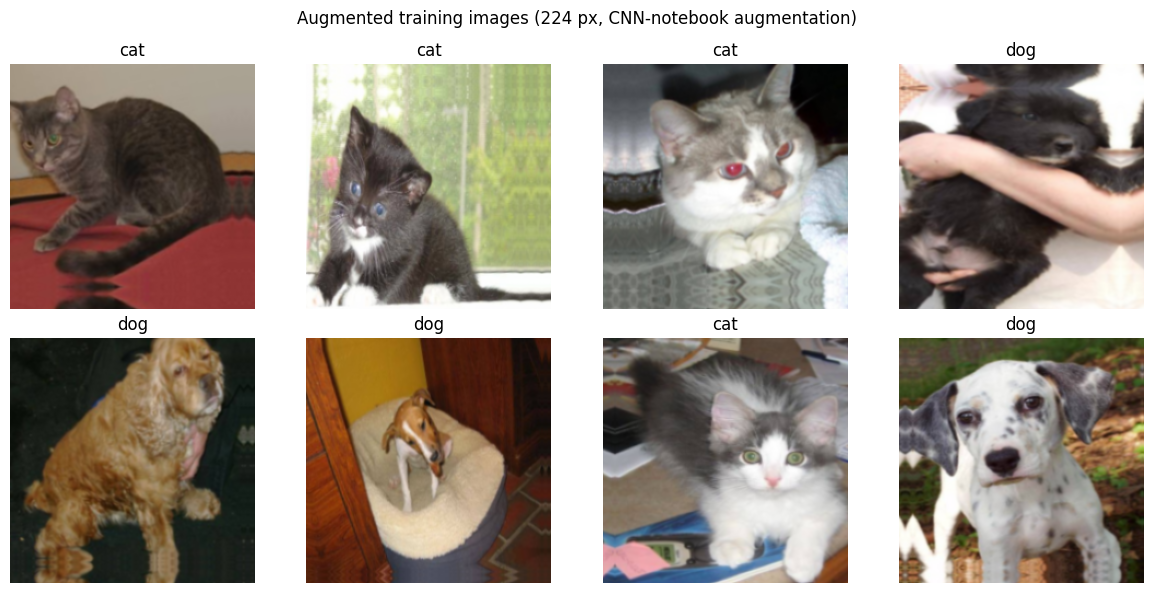

In [ ]:
# Preview: one augmented training batch
preview_loader = make_loader(train_paths, train_labels, train_transform, shuffle=True)
images, labels = next(iter(preview_loader))
images = make_augment()(images.to(DEVICE)).cpu()   # same augmentation as training

mean = torch.tensor(MEAN).view(3, 1, 1)
std = torch.tensor(STD).view(3, 1, 1)

fig, axes = plt.subplots(2, 4, figsize=(12, 6))
for ax, image, label in zip(axes.flat, images[:8], labels[:8]):
    ax.imshow((image * std + mean).clamp(0, 1).permute(1, 2, 0).numpy())
    ax.set_title(CLASS_NAMES[int(label)])
    ax.axis("off")
fig.suptitle(f"Augmented training images ({INPUT_SIZE[0]} px, CNN-notebook augmentation)")
plt.tight_layout()
plt.show()
del preview_loader

## 6. Training and evaluation

### 6.1 Efficiency metrics
Measured for every run, so the CNN and ViT can be compared on deployment cost as well as accuracy:
- **Parameters** and **model size** (MB, assuming float32 weights).
- **GFLOPs** for one image.
- **Latency:** median time to classify a single image on CPU and GPU, over 50 runs after 10 warm-up runs. Colab's CPU has only 2 cores, so treat CPU latency as a relative comparison.

In [ ]:
def count_params(model):
    return sum(p.numel() for p in model.parameters())


def model_size_mb(model):
    return count_params(model) * 4 / 1e6   # float32 = 4 bytes per weight


def count_gflops(model):
    try:
        from torch.utils.flop_counter import FlopCounterMode
        model = model.eval().to("cpu")
        x = torch.randn(1, 3, *INPUT_SIZE)
        with torch.no_grad(), FlopCounterMode(display=False) as counter:
            model(x)
        return counter.get_total_flops() / 1e9
    except Exception as error:
        print("FLOP count skipped:", error)
        return float("nan")


@torch.no_grad()
def measure_latency_ms(model, device, runs=50, warmup=10):
    model = model.eval().to(device)
    x = torch.randn(1, 3, *INPUT_SIZE, device=device)
    for _ in range(warmup):
        model(x)
    times = []
    for _ in range(runs):
        if device.type == "cuda":
            torch.cuda.synchronize()
        start = time.perf_counter()
        model(x)
        if device.type == "cuda":
            torch.cuda.synchronize()
        times.append((time.perf_counter() - start) * 1000)
    return float(np.median(times))

### 6.2 Training utilities
- `evaluate` returns validation loss, accuracy (threshold 0.5) and ROC AUC.
- `make_scheduler` raises the learning rate linearly over `WARMUP_EPOCHS`, then decays it along a cosine curve to zero at `EPOCHS`. This replaces the CNN notebook's ReduceLROnPlateau and is the usual schedule for fine-tuning transformers.
- `smooth_targets` applies label smoothing in the same way as Keras' `BinaryCrossentropy(label_smoothing=...)`.
- `log_result` and `summarize_results` use the same `results.csv` as the CNN notebook, so runs from both notebooks appear in one table.
- Training accuracy is measured with augmentation active, so it can sit slightly below validation accuracy early in training. This is expected.

In [ ]:
def smooth_targets(y, smoothing):
    return y * (1 - smoothing) + 0.5 * smoothing


@torch.no_grad()
def evaluate(model, loader, criterion=None):
    model.eval()
    probs, targets, total_loss, count = [], [], 0.0, 0
    for x, y in loader:
        x, y = x.to(DEVICE, non_blocking=True), y.to(DEVICE, non_blocking=True)
        with torch.autocast(device_type=DEVICE.type, dtype=torch.float16, enabled=AMP_ENABLED):
            logits = model(x).squeeze(1)
        logits = logits.float()
        if criterion is not None:
            total_loss += criterion(logits, y).item() * len(y)
            count += len(y)
        probs.append(torch.sigmoid(logits).cpu())
        targets.append(y.cpu())
    probs = torch.cat(probs).numpy()
    targets = torch.cat(targets).numpy()
    result = {"probs": probs}
    if criterion is not None:
        preds = (probs >= 0.5).astype(int)
        result.update(loss=total_loss / count,
                      accuracy=float((preds == targets).mean()),
                      auc=float(roc_auc_score(targets, probs)))
    return result


def make_scheduler(optimizer, steps_per_epoch):
    warmup = WARMUP_EPOCHS * steps_per_epoch
    total = EPOCHS * steps_per_epoch

    def lr_factor(step):
        if step < warmup:
            return (step + 1) / warmup
        progress = (step - warmup) / max(1, total - warmup)
        return 0.5 * (1 + np.cos(np.pi * min(1.0, progress)))

    return torch.optim.lr_scheduler.LambdaLR(optimizer, lr_factor)


def log_result(record, path=RESULTS_PATH):
    row = pd.DataFrame([record])
    if path.exists():
        row = pd.concat([pd.read_csv(path), row], ignore_index=True)
    row.to_csv(path, index=False)


def plot_history(hist, title, save=True):
    best = int(hist["val_loss"].idxmin()) + 1
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    for ax, key, label in [(axes[0], "loss", "Loss"), (axes[1], "accuracy", "Accuracy")]:
        ax.plot(hist["epoch"], hist[key], label="train")
        ax.plot(hist["epoch"], hist[f"val_{key}"], label="validation")
        ax.axvline(best, color="grey", linestyle="--", label=f"best epoch ({best})")
        ax.set_xlabel("Epoch")
        ax.set_ylabel(label)
        ax.grid(alpha=0.3)
        ax.legend()
    fig.suptitle(title)
    fig.tight_layout()
    if save:
        fig.savefig(FIGURE_DIR / f"{title}.png", dpi=150)
    plt.show()


def summarize_results(path=RESULTS_PATH, metrics=("val_acc", "val_auc")):
    # Mean, std and run count per configuration (run_name), across both notebooks.
    df = pd.read_csv(path)
    present = [m for m in metrics if m in df and df[m].notna().any()]
    return df.groupby("run_name")[present].agg(["mean", "std", "count"]).round(4)

### 6.3 Experiment runner
`run_experiment` performs one complete run:
- Seeds everything and loads fresh pretrained weights. **All layers are fine-tuned**, using AdamW and mixed precision.
- Evaluates on the validation set after every epoch and stops early when validation loss has not improved for `EARLY_STOP_PATIENCE` epochs.
- Saves the best epoch's weights to Drive and reloads them before scoring (the PyTorch equivalent of Keras' `restore_best_weights=True`).
- Logs accuracy, AUC and the efficiency metrics as one row in `results.csv`, and saves the per-epoch history as a CSV.

In [ ]:
def run_experiment(run_name=RUN_NAME, seed=SEED, verbose=True):
    set_seed(seed)
    model = build_model(pretrained=True).to(DEVICE)
    train_loader = make_loader(train_paths, train_labels, train_transform, shuffle=True, seed=seed)
    augment = make_augment()

    criterion = nn.BCEWithLogitsLoss()
    optimizer = torch.optim.AdamW(model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)
    scheduler = make_scheduler(optimizer, len(train_loader))
    scaler = torch.amp.GradScaler("cuda", enabled=AMP_ENABLED)

    checkpoint = CHECKPOINT_DIR / f"{run_name}_s{seed}.pt"
    history, best_loss, best_epoch, waited = [], float("inf"), 0, 0
    start = time.time()

    for epoch in range(1, EPOCHS + 1):
        model.train()
        epoch_start = time.time()
        total_loss, correct, count = 0.0, 0, 0
        for x, y in train_loader:
            x, y = x.to(DEVICE, non_blocking=True), y.to(DEVICE, non_blocking=True)
            x = augment(x)   # float32, outside autocast, as in the CNN notebook
            optimizer.zero_grad(set_to_none=True)
            with torch.autocast(device_type=DEVICE.type, dtype=torch.float16, enabled=AMP_ENABLED):
                logits = model(x).squeeze(1)
            logits = logits.float()
            loss = criterion(logits, smooth_targets(y, LABEL_SMOOTHING))
            scaler.scale(loss).backward()
            scaler.step(optimizer)
            scaler.update()
            scheduler.step()

            total_loss += loss.item() * len(y)
            correct += ((logits >= 0).float() == y).sum().item()
            count += len(y)

        val = evaluate(model, val_loader, criterion)
        row = {"epoch": epoch, "loss": total_loss / count, "accuracy": correct / count,
               "val_loss": val["loss"], "val_accuracy": val["accuracy"], "val_auc": val["auc"],
               "learning_rate": optimizer.param_groups[0]["lr"]}
        history.append(row)

        improved = val["loss"] < best_loss
        if improved:
            best_loss, best_epoch, waited = val["loss"], epoch, 0
            torch.save(model.state_dict(), checkpoint)
        else:
            waited += 1

        if verbose:
            print(f"Epoch {epoch:>2}/{EPOCHS} - {time.time() - epoch_start:.0f}s - "
                  f"loss {row['loss']:.4f} - acc {row['accuracy']:.4f} - "
                  f"val_loss {row['val_loss']:.4f} - val_acc {row['val_accuracy']:.4f} - "
                  f"val_auc {row['val_auc']:.4f}" + ("  *best" if improved else ""))

        if waited >= EARLY_STOP_PATIENCE:
            print(f"Early stopping: no improvement for {EARLY_STOP_PATIENCE} epochs.")
            break

    train_minutes = (time.time() - start) / 60
    hist = pd.DataFrame(history)
    hist.to_csv(FIGURE_DIR / f"history_{run_name}_s{seed}.csv", index=False)

    # Reload the best epoch's weights and score them.
    model.load_state_dict(torch.load(checkpoint, map_location=DEVICE))
    val = evaluate(model, val_loader, criterion)

    gflops = count_gflops(model)
    cpu_ms = measure_latency_ms(model, torch.device("cpu"))
    gpu_ms = measure_latency_ms(model, DEVICE) if DEVICE.type == "cuda" else float("nan")
    model.to(DEVICE)

    record = {
        "timestamp": time.strftime("%Y-%m-%d %H:%M"),
        "run_name": run_name,
        "seed": seed,
        "model": MODEL_NAME,
        "params": count_params(model),
        "image_size": INPUT_SIZE[0],
        "train_images": len(train_paths),
        "experiment": EXPERIMENT,
        "learning_rate": LEARNING_RATE,
        "weight_decay": WEIGHT_DECAY,
        "label_smoothing": LABEL_SMOOTHING,
        "epochs_run": len(hist),
        "best_epoch": best_epoch,
        "train_minutes": round(train_minutes, 2),
        "val_loss": round(val["loss"], 4),
        "val_acc": round(val["accuracy"], 4),
        "val_auc": round(val["auc"], 4),
        "model_size_mb": round(model_size_mb(model), 2),
        "gflops": round(gflops, 3),
        "latency_cpu_ms": round(cpu_ms, 2),
        "latency_gpu_ms": round(gpu_ms, 2),
        "augmentation": str(AUGMENTATION),
    }
    log_result(record)
    print(f"\n{run_name} (seed {seed}): val acc {record['val_acc']:.4f}, "
          f"val AUC {record['val_auc']:.4f}, best epoch {best_epoch}, "
          f"{record['train_minutes']} min")
    print(f"Params {record['params']:,} | {record['model_size_mb']} MB | "
          f"{record['gflops']} GFLOPs | CPU {record['latency_cpu_ms']} ms | "
          f"GPU {record['latency_gpu_ms']} ms per image")
    return model, hist, record

### 6.4 Train the ViT
One run with the settings from Section 1. The best checkpoint, training curves, history and results row are saved to Drive.

model.safetensors: reconstructing file:   0%|          |  0.00B / 22.9MB            

model.safetensors: downloading bytes:           |  0.00B            

Epoch  1/10 - 38s - loss 0.2014 - acc 0.9192 - val_loss 0.0683 - val_acc 0.9770 - val_auc 0.9973  *best
Epoch  2/10 - 37s - loss 0.0907 - acc 0.9682 - val_loss 0.0709 - val_acc 0.9735 - val_auc 0.9971
Epoch  3/10 - 36s - loss 0.0632 - acc 0.9764 - val_loss 0.0588 - val_acc 0.9785 - val_auc 0.9975  *best
Epoch  4/10 - 35s - loss 0.0386 - acc 0.9856 - val_loss 0.0519 - val_acc 0.9810 - val_auc 0.9985  *best
Epoch  5/10 - 39s - loss 0.0350 - acc 0.9884 - val_loss 0.0580 - val_acc 0.9790 - val_auc 0.9978
Epoch  6/10 - 36s - loss 0.0211 - acc 0.9938 - val_loss 0.0694 - val_acc 0.9775 - val_auc 0.9977
Epoch  7/10 - 35s - loss 0.0113 - acc 0.9970 - val_loss 0.0622 - val_acc 0.9810 - val_auc 0.9980
Early stopping: no improvement for 3 epochs.

deit_tiny_patch16_224_n2500_cnnaug (seed 41): val acc 0.9810, val AUC 0.9985, best epoch 4, 4.28 min
Params 5,524,609 | 22.1 MB | 2.149 GFLOPs | CPU 43.32 ms | GPU 6.41 ms per image


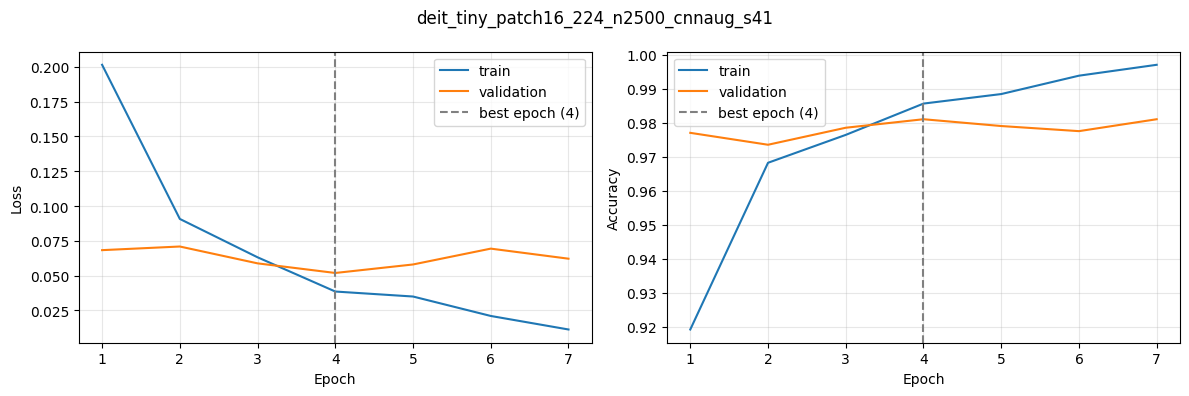

In [ ]:
vit_model, vit_history, vit_record = run_experiment()
plot_history(vit_history, f"{RUN_NAME}_s{SEED}")

### 6.5 Repeat over seeds
Off by default so *Run all* doesn't start several long training runs. Set `RUN_SEED_SWEEP = True` to repeat a configuration over three seeds and report mean ± std.

In [ ]:
RUN_SEED_SWEEP = False
SWEEP_SEEDS = [41, 42, 43]

if RUN_SEED_SWEEP:
    for seed in SWEEP_SEEDS:
        if seed == SEED:
            continue   # already trained above
        run_experiment(seed=seed, verbose=False)

summarize_results()

val_acc               val_auc              
                                      mean     std count    mean     std count
run_name                                                                      
deit_tiny_patch16_224_n2500         0.9810  0.0064     2  0.9978  0.0008     2
deit_tiny_patch16_224_n2500_cnnaug  0.9810     NaN     1  0.9985     NaN     1
vgg_baseline                        0.7840     NaN     1  0.8578     NaN     1
vgg_baseline_n1000                  0.7800     NaN     1  0.8547     NaN     1
vgg_baseline_n2500                  0.8530     NaN     1  0.9256     NaN     1
vgg_baseline_n2500_lr5e-4           0.8575     NaN     1  0.9315     NaN     1
vgg_baseline_n2500_lr5e-4_ls0.1     0.8795     NaN     1  0.9548     NaN     1

## 7. Results and predictions

### 7.1 Compare runs
Every run logged by both notebooks, side by side: accuracy, AUC, model size, compute and latency.

In [ ]:
columns = ["run_name", "seed", "model", "params", "image_size", "train_images",
           "val_acc", "val_auc", "model_size_mb", "gflops", "latency_cpu_ms", "latency_gpu_ms"]
all_runs = pd.read_csv(RESULTS_PATH)
all_runs[[c for c in columns if c in all_runs.columns]]

,run_name,seed,model,params,image_size,train_images,val_acc,val_auc,model_size_mb,gflops,latency_cpu_ms,latency_gpu_ms
0,vgg_baseline,41,vgg_baseline,1175393,224,2000,0.7840,0.8578,NaN,NaN,NaN,NaN
1,vgg_baseline_n1000,41,vgg_baseline,1175393,224,2000,0.7800,0.8547,NaN,NaN,NaN,NaN
2,vgg_baseline_n2500,41,vgg_baseline,1175393,224,5000,0.8530,0.9256,NaN,NaN,NaN,NaN
3,vgg_baseline_n2500_lr5e-4,41,vgg_baseline,1175393,224,5000,0.8575,0.9315,NaN,NaN,NaN,NaN
4,vgg_baseline_n2500_lr5e-4_ls0.1,41,vgg_baseline,1175393,224,5000,0.8795,0.9548,NaN,NaN,NaN,NaN
5,deit_tiny_patch16_224_n2500,41,deit_tiny_patch16_224,5524609,224,5000,0.9765,0.9973,22.1,2.149,35.41,5.08
6,deit_tiny_patch16_224_n2500,41,deit_tiny_patch16_224,5524609,224,5000,0.9855,0.9984,22.1,2.149,34.43,5.13
7,deit_tiny_patch16_224_n2500_cnnaug,41,deit_tiny_patch16_224,5524609,224,5000,0.9810,0.9985,22.1,2.149,43.32,6.41


### 7.2 Predictions and submission
- If the session was restarted after training, the best checkpoint is reloaded from Drive.
- Validation predictions are saved to `predictions/`, sorted by confidence, for picking correctly and incorrectly classified examples for error analysis.
- Test predictions are saved to `predictions/` as well (1 = dog, 0 = cat).
- `submission_<RUN_NAME>.csv` is written only when `WRITE_SUBMISSION = True`, so the CNN's `submission.csv` is never overwritten.

In [ ]:
if "vit_model" not in globals():
    # Session was restarted after training: load the best saved weights from Drive
    checkpoint = CHECKPOINT_DIR / f"{RUN_NAME}_s{SEED}.pt"
    if not checkpoint.exists():
        raise FileNotFoundError(f"No checkpoint found: {checkpoint}. Run the training cell first.")
    vit_model = build_model(pretrained=False).to(DEVICE)
    vit_model.load_state_dict(torch.load(checkpoint, map_location=DEVICE))
    print("Loaded best checkpoint:", checkpoint.name)

val_out = evaluate(vit_model, val_loader)
val_df = pd.DataFrame({"path": [str(p) for p in val_paths], "label": val_labels,
                       "prob_dog": val_out["probs"]})
val_df["pred"] = (val_df["prob_dog"] >= 0.5).astype(int)
val_df["correct"] = val_df["pred"] == val_df["label"]
val_df["confidence"] = np.where(val_df["pred"] == 1, val_df["prob_dog"], 1 - val_df["prob_dog"])
val_df.sort_values("confidence", ascending=False).to_csv(
    PREDICTION_DIR / f"val_{RUN_NAME}_s{SEED}.csv", index=False)
print(f"Validation accuracy: {val_df['correct'].mean():.4f}")

test_out = evaluate(vit_model, test_loader)
test_pred = (test_out["probs"] >= 0.5).astype(int)
if len(test_pred) != len(test_ids):
    raise ValueError("Prediction count does not match the number of test images.")
test_df = pd.DataFrame({"id": test_ids, "path": [str(p) for p in test_paths],
                        "prob_dog": test_out["probs"], "pred": test_pred})
test_df.to_csv(PREDICTION_DIR / f"test_{RUN_NAME}_s{SEED}.csv", index=False)

if WRITE_SUBMISSION:
    path = PROJECT_DIR / f"submission_{RUN_NAME}.csv"
    pd.DataFrame({"id": test_ids, "label": test_pred}).to_csv(path, index=False)
    print(f"Wrote {len(test_pred)} rows to {path} "
          f"({test_pred.sum()} dogs, {len(test_pred) - test_pred.sum()} cats)")

Validation accuracy: 0.9810
